# 00: Fundamental 3D Representations in Computer Vision & Geometry Processing

**Course:** IF5152 - 3D Computer Vision  
**Notebook:** `00_3d_representations.ipynb`  
**Focus:** Comprehensive mathematical foundations, Python implementations, and empirical trade-offs across all 3D geometry and scene representations.

---

## 1. Why 3D Representation Matters

Choosing how to represent 3D geometry directly dictates:
1. **Storage & Memory Efficiency**: Compact surface boundaries vs. cubic spatial grids.
2. **Creation & Sampling**: How easily we can synthesize new shapes or sample points on the surface.
3. **Geometric Operations**: Complexity of Boolean unions, intersections, subdivision, smoothing, and deformation.
4. **Rendering**: Rasterization, ray tracing, sphere tracing, or neural volume rendering.

```mermaid
graph TD
    GEO["3D Geometry Representations"] --> EXP["Explicit (Lagrangian)<br/>All surface points/elements given directly"]
    GEO --> IMP["Implicit (Eulerian)<br/>Points classified by function f(x, y, z) = 0"]
    GEO --> HYB["Modern Scene & Deep Primitives"]

    EXP --> EXP_PC["Point Clouds & Surfels<br/>(k-NN, FPS, Normal PCA)"]
    EXP --> EXP_MESH["Polygonal Meshes<br/>(Subdivision, Decimation, Smoothing)"]
    EXP --> EXP_PARAM["Parametric Surfaces<br/>(Bézier Patches, Torus/Sphere UV)"]

    IMP --> IMP_CSG["Algebraic Surfaces & CSG<br/>(Exact & Smooth Min Blending)"]
    IMP --> IMP_SDF["Signed Distance Functions (SDF)<br/>(Eikonal Metric, Sphere Tracing)"]
    IMP --> IMP_VOX["Volumetric Grids & Octrees<br/>(Occupancy Grids & Spatial Partitioning)"]

    HYB --> HYB_MV["Multi-View 2D Projections (Orbiting Cameras)"]
    HYB --> HYB_GS["3D Gaussian Splatting Primitives"]
    HYB --> HYB_STR["Structure-Aware Part Primitives"]
```

---

## 2. Standard Industry Python Libraries Used
- **`trimesh`**: The industry-standard Python library for loading, creating, editing, and analyzing triangular meshes and scene graphs.
- **`open3d`**: The premier industrial framework for 3D data processing, point cloud registration, and spatial algorithms.
- **`scipy.spatial`**: High-performance spatial KD-trees, nearest neighbors, Convex Hulls, and Delaunay triangulations.
- **`skimage.measure`**: Marching Cubes algorithm for extracting explicit polygon meshes from continuous scalar fields.
- **`numpy` & `torch`**: Vectorized geometric tensor math, linear algebra, and coordinate transformations.
- **`matplotlib`**: 3D publication-quality visualization (`Poly3DCollection`, `Line3DCollection`, `voxels`, 3D scatter, quivers).


In [10]:
import os
import sys
import time
import math
import numpy as np
import scipy
from scipy.spatial import KDTree, ConvexHull
import torch
import trimesh
from skimage import measure
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection

# Optional industrial Open3D support
try:
    import open3d as o3d
    HAS_OPEN3D = True
    o3d_version = o3d.__version__
except ImportError:
    HAS_OPEN3D = False
    o3d_version = "N/A"

# Set seeds for deterministic reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Verify compute device
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

print("=" * 65)
print(f"NumPy Version    : {np.__version__}")
print(f"SciPy Version    : {scipy.__version__}")
print(f"PyTorch Version  : {torch.__version__} (Device: {device})")
print(f"Trimesh Version  : {trimesh.__version__}")
print(f"Open3D Version   : {o3d_version} (Available: {HAS_OPEN3D})")
print("=" * 65)

# Configure plot styling
plt.rcParams.update({
    "font.size": 10,
    "figure.titlesize": 12,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.autolayout": False,
})

def create_3d_axes(num_subplots: int = 4, figsize=(18, 4.5)):
    fig = plt.figure(figsize=figsize)
    axes = [fig.add_subplot(1, num_subplots, i + 1, projection="3d") for i in range(num_subplots)]
    return fig, axes

def set_3d_bounds(ax, bound=1.0, title=""):
    ax.set_xlim(-bound, bound)
    ax.set_ylim(-bound, bound)
    ax.set_zlim(-bound, bound)
    ax.set_title(title, pad=10, fontweight="bold")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.grid(True, linestyle="--", alpha=0.3)


NumPy Version    : 2.4.6
SciPy Version    : 1.17.1
PyTorch Version  : 2.15.0 (Device: mps)
Trimesh Version  : 5.2.1
Open3D Version   : 0.20.0 (Available: True)


## Section 1: Explicit Representations: Point Clouds & Surfels

A **Point Cloud** is an unordered collection of $N$ spatial coordinates:
$$\mathcal{P} = \{ \mathbf{p}_i = (x_i, y_i, z_i) \in \mathbb{R}^3 \}_{i=1}^N$$

When points are augmented with oriented surface normals $\mathbf{n}_i \in \mathbb{S}^2$ and optional attributes (RGB color $\mathbf{c}_i \in [0, 1]^3$, curvature $r_i$), they are termed **Surfels** (Surface Elements).

### 1.1 Key Invariances & Challenges
1. **Permutation Invariance**: Reordering the $N$ rows does not change the physical shape ($N!$ equivalent representations).
2. **Sampling Invariance**: Density variations across scanning regions should not alter semantic perception.
3. **No Explicit Topology**: Point clouds do not store surface connectivity or triangle edges.

### 1.2 Surface Normal Estimation via Local PCA
For each point $\mathbf{p}_i$, we gather its $k$-nearest neighbors $\mathcal{N}_k(\mathbf{p}_i)$ using a spatial KD-tree. The local covariance matrix is:
$$\mathbf{C}_i = \frac{1}{k} \sum_{\mathbf{q} \in \mathcal{N}_k(\mathbf{p}_i)} (\mathbf{q} - \bar{\mathbf{p}}_i)(\mathbf{q} - \bar{\mathbf{p}}_i)^T, \quad \bar{\mathbf{p}}_i = \frac{1}{k} \sum_{\mathbf{q} \in \mathcal{N}_k(\mathbf{p}_i)} \mathbf{q}$$

The eigendecomposition $\mathbf{C}_i \mathbf{v}_j = \lambda_j \mathbf{v}_j$ ($0 \le \lambda_0 \le \lambda_1 \le \lambda_2$) yields:
- The eigenvector $\mathbf{v}_0$ corresponding to the smallest eigenvalue $\lambda_0$ points along the direction of **least variance**, which estimates the local surface normal $\mathbf{n}_i \approx \mathbf{v}_0$.

### 1.3 Downsampling Strategies
- **Voxel Downsampling**: Discretizes bounding space into regular voxels of side length $s_v$ and replaces all points inside a voxel with their centroid. Complexity is $\mathcal{O}(N)$.
- **Farthest Point Sampling (FPS)**: Iteratively selects points that maximize the minimum distance to already selected points:
$$\mathbf{p}_{m+1} = \operatorname{arg\,max}_{\mathbf{p} \in \mathcal{P}} \min_{j=1}^m \|\mathbf{p} - \mathbf{s}_j\|_2$$
FPS provides optimal geometric diversity coverage for point neural backbones (e.g. PointNet++).


[Open3D] PointCloud initialized: 4000 points with normal vectors.


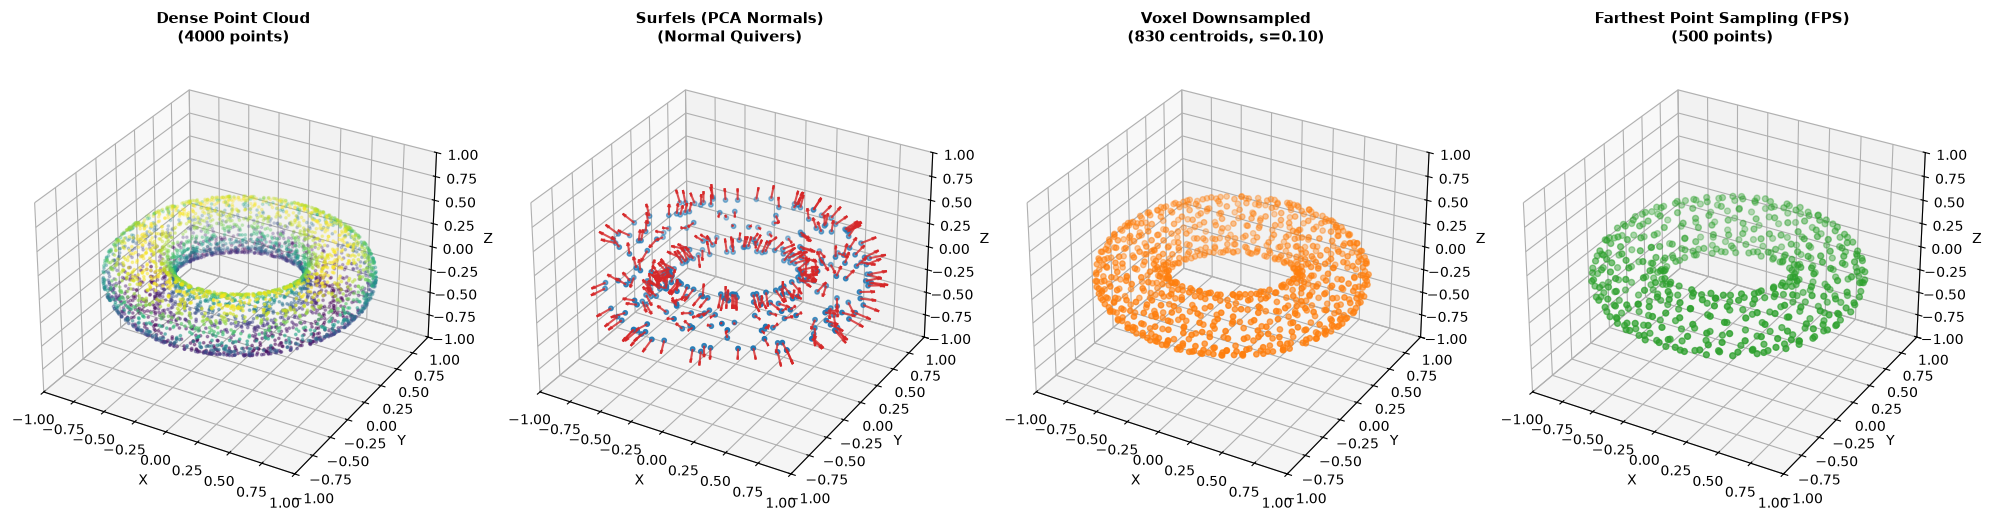

In [11]:
# 1. Generate an analytical 3D torus point cloud
def generate_torus_pointcloud(num_points=4000, R=0.7, r=0.25):
    u = np.random.uniform(0, 2 * np.pi, num_points)
    v = np.random.uniform(0, 2 * np.pi, num_points)
    x = (R + r * np.cos(v)) * np.cos(u)
    y = (R + r * np.cos(v)) * np.sin(u)
    z = r * np.sin(v)
    return np.stack([x, y, z], axis=-1)

pts_dense = generate_torus_pointcloud(num_points=4000)

# 2. Surface Normal Estimation via Local PCA
def estimate_point_normals(pts: np.ndarray, k: int = 16) -> np.ndarray:
    tree = KDTree(pts)
    _, idxs = tree.query(pts, k=k)
    normals = np.zeros_like(pts)
    
    for i in range(len(pts)):
        neighbors = pts[idxs[i]]  # (k, 3)
        centered = neighbors - neighbors.mean(axis=0, keepdims=True)
        cov = (centered.T @ centered) / k
        eigenvalues, eigenvectors = np.linalg.eigh(cov)
        n = eigenvectors[:, 0]
        if np.dot(n, pts[i]) < 0:
            n = -n
        normals[i] = n / (np.linalg.norm(n) + 1e-8)
    return normals

normals = estimate_point_normals(pts_dense, k=16)

# Open3D PointCloud Bridge
if HAS_OPEN3D:
    pcd_o3d = o3d.geometry.PointCloud()
    pcd_o3d.points = o3d.utility.Vector3dVector(pts_dense)
    pcd_o3d.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamKNN(knn=16))
    print(f"[Open3D] PointCloud initialized: {len(pcd_o3d.points)} points with normal vectors.")

# 3. Voxel Grid Downsampling
def voxel_downsample(pts: np.ndarray, voxel_size: float = 0.1) -> np.ndarray:
    voxel_indices = np.floor(pts / voxel_size).astype(np.int32)
    unique_voxels, inverse_indices = np.unique(voxel_indices, axis=0, return_inverse=True)
    downsampled = np.zeros((len(unique_voxels), 3), dtype=np.float32)
    counts = np.zeros(len(unique_voxels), dtype=np.float32)
    for i, v_idx in enumerate(inverse_indices):
        downsampled[v_idx] += pts[i]
        counts[v_idx] += 1
    return downsampled / counts[:, None]

pts_voxel = voxel_downsample(pts_dense, voxel_size=0.10)

# 4. Farthest Point Sampling (FPS)
def farthest_point_sampling(pts: np.ndarray, num_samples: int = 500) -> np.ndarray:
    n = len(pts)
    selected_indices = [np.random.randint(0, n)]
    distances = np.linalg.norm(pts - pts[selected_indices[0]], axis=-1)
    
    for _ in range(1, num_samples):
        next_idx = np.argmax(distances)
        selected_indices.append(next_idx)
        new_dists = np.linalg.norm(pts - pts[next_idx], axis=-1)
        distances = np.minimum(distances, new_dists)
        
    return pts[selected_indices]

pts_fps = farthest_point_sampling(pts_dense, num_samples=500)

# Visualizations
fig, axes = create_3d_axes(num_subplots=4, figsize=(20, 5))

# Plot 1: Dense Point Cloud
axes[0].scatter(pts_dense[:, 0], pts_dense[:, 1], pts_dense[:, 2], c=pts_dense[:, 2], cmap="viridis", s=3, alpha=0.7)
set_3d_bounds(axes[0], bound=1.0, title=f"Dense Point Cloud\n({len(pts_dense)} points)")

# Plot 2: Surfels (Points + Normal Quivers)
sub_idx = np.random.choice(len(pts_dense), 300, replace=False)
axes[1].scatter(pts_dense[sub_idx, 0], pts_dense[sub_idx, 1], pts_dense[sub_idx, 2], c="tab:blue", s=10)
axes[1].quiver(
    pts_dense[sub_idx, 0], pts_dense[sub_idx, 1], pts_dense[sub_idx, 2],
    normals[sub_idx, 0], normals[sub_idx, 1], normals[sub_idx, 2],
    length=0.12, color="tab:red", alpha=0.8, normalize=True
)
set_3d_bounds(axes[1], bound=1.0, title="Surfels (PCA Normals)\n(Normal Quivers)")

# Plot 3: Voxel Downsampled
axes[2].scatter(pts_voxel[:, 0], pts_voxel[:, 1], pts_voxel[:, 2], c="tab:orange", s=15, alpha=0.9)
set_3d_bounds(axes[2], bound=1.0, title=f"Voxel Downsampled\n({len(pts_voxel)} centroids, s=0.10)")

# Plot 4: Farthest Point Sampling
axes[3].scatter(pts_fps[:, 0], pts_fps[:, 1], pts_fps[:, 2], c="tab:green", s=18, alpha=0.9)
set_3d_bounds(axes[3], bound=1.0, title=f"Farthest Point Sampling (FPS)\n({len(pts_fps)} points)")

plt.tight_layout()
plt.show()


In [6]:
HAS_OPEN3D

True

## Section 2: Explicit Representations: Polygonal Meshes (Boundary Representation)

A **Polygonal Mesh** represents 3D surfaces as a collection of vertices $\mathcal{V}$, edges $\mathcal{E}$, and faces $\mathcal{F}$:
$$\mathcal{M} = (\mathcal{V}, \mathcal{F}), \quad \mathcal{V} \in \mathbb{R}^{|\mathcal{V}| \times 3}, \quad \mathcal{F} \in \mathbb{Z}^{|\mathcal{F}| \times 3}$$

### 2.1 Topological Invariants: Genus & Euler Characteristic
The **Euler characteristic** $\chi$ is an intrinsic topological invariant:
$$\chi = |\mathcal{V}| - |\mathcal{E}| + |\mathcal{F}| = 2 - 2g$$
where $g$ is the **genus** (number of through-holes):
- Sphere or Cube: $g = 0 \implies \chi = 2$.
- Torus: $g = 1 \implies \chi = 0$.

### 2.2 Core Geometric Operations
1. **Subdivision (Upsampling)**:
   Increases triangle density by splitting existing triangles (e.g. inserting edge midpoints) and interpolating vertex positions to approximate a smooth limit surface.
2. **Mesh Simplification / Decimation (Downsampling)**:
   Iteratively contracts edges based on the **Quadric Error Metric (QEM)** (Garland & Heckbert), reducing triangle count while maintaining silhouette and surface curvature.
3. **Laplacian Smoothing (Regularization)**:
   Diffuses high-frequency surface noise by updating vertex positions toward the average of their 1-ring neighbors:
   $$\mathbf{v}_i^{(t+1)} = \mathbf{v}_i^{(t)} + \lambda \sum_{j \in \mathcal{N}(i)} w_{ij} (\mathbf{v}_j^{(t)} - \mathbf{v}_i^{(t)})$$
   - *Uniform weights:* $w_{ij} = \frac{1}{|\mathcal{N}(i)|}$.
   - *Cotangent weights:* Accounts for triangle aspect ratios and dihedral angles.


[Base Mesh] Vertices: 42, Edges: 120, Faces: 80
[Topology]  Euler Characteristic χ = 2, Genus g = 0, Watertight = True
[Subdivided] Vertices: 162, Faces: 320
[Simplified] Faces reduced from 320 down to 272


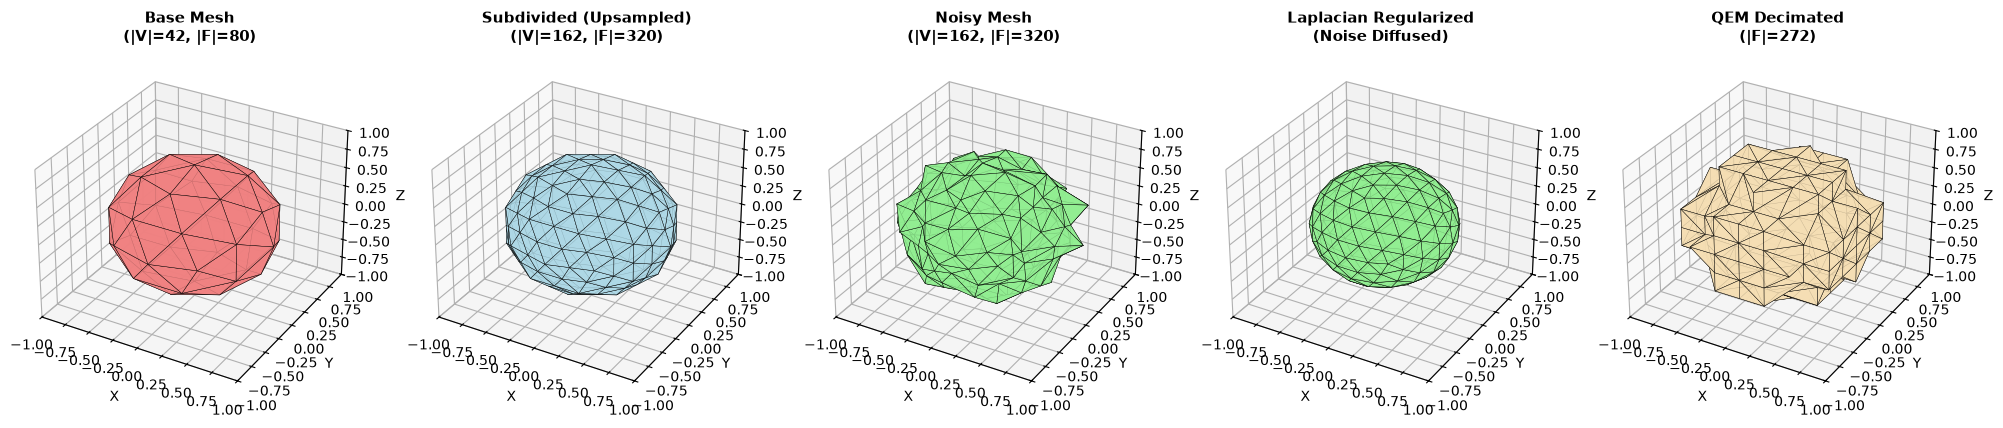

In [13]:
# 1. Create a base polygonal mesh (Low-poly icosphere)
mesh_base = trimesh.creation.icosphere(subdivisions=1, radius=0.8)

# Calculate Euler characteristic and topological genus
num_v = len(mesh_base.vertices)
num_f = len(mesh_base.faces)
num_e = len(mesh_base.edges_unique)
euler_chi = num_v - num_e + num_f
genus = (2 - euler_chi) // 2

print(f"[Base Mesh] Vertices: {num_v}, Edges: {num_e}, Faces: {num_f}")
print(f"[Topology]  Euler Characteristic χ = {euler_chi}, Genus g = {genus}, Watertight = {mesh_base.is_watertight}")

# 2. Subdivision (Upsampling via midpoint refinement)
mesh_subdivided = mesh_base.subdivide()
print(f"[Subdivided] Vertices: {len(mesh_subdivided.vertices)}, Faces: {len(mesh_subdivided.faces)}")

# 3. Add synthetic geometric noise to demonstrate Laplacian Smoothing
noisy_verts = mesh_subdivided.vertices.copy()
noise = np.random.normal(0.0, 0.05, size=noisy_verts.shape)
noisy_verts += noise
mesh_noisy = trimesh.Trimesh(vertices=noisy_verts, faces=mesh_subdivided.faces, process=False)

# 4. Implement Uniform Laplacian Smoothing
def laplacian_smooth(mesh: trimesh.Trimesh, iterations: int = 5, lamb: float = 0.5) -> trimesh.Trimesh:
    v = mesh.vertices.copy()
    adj = mesh.vertex_neighbors
    for _ in range(iterations):
        v_new = v.copy()
        for i in range(len(v)):
            neighbors = adj[i]
            if len(neighbors) > 0:
                v_new[i] = (1.0 - lamb) * v[i] + lamb * np.mean(v[neighbors], axis=0)
        v = v_new
    return trimesh.Trimesh(vertices=v, faces=mesh.faces, process=False)

mesh_smoothed = laplacian_smooth(mesh_noisy, iterations=6, lamb=0.5)

# 5. Mesh Simplification via Decimation (with graceful fallback)
def simplify_mesh(mesh: trimesh.Trimesh, target_faces: int = 24) -> trimesh.Trimesh:
    try:
        return mesh.simplify_quadric_decimation(face_count=target_faces)
    except Exception:
        grid_size = 0.25
        quantized = np.round(mesh.vertices / grid_size) * grid_size
        unique_verts, inverse = np.unique(quantized, axis=0, return_inverse=True)
        new_faces = inverse[mesh.faces]
        valid = (new_faces[:, 0] != new_faces[:, 1]) & (new_faces[:, 1] != new_faces[:, 2]) & (new_faces[:, 0] != new_faces[:, 2])
        return trimesh.Trimesh(vertices=unique_verts, faces=new_faces[valid], process=True)

mesh_simplified = simplify_mesh(mesh_subdivided, target_faces=24)
print(f"[Simplified] Faces reduced from {len(mesh_subdivided.faces)} down to {len(mesh_simplified.faces)}")

# Visualization
def plot_mesh_collection(ax, mesh, color="lightsteelblue", edge_color="black", alpha=0.85):
    triangles = mesh.vertices[mesh.faces]
    poly = Poly3DCollection(triangles, facecolor=color, edgecolor=edge_color, linewidths=0.3, alpha=alpha)
    ax.add_collection3d(poly)

fig, axes = create_3d_axes(num_subplots=5, figsize=(20, 5))

# Plot 1: Base Low-Poly Mesh
plot_mesh_collection(axes[0], mesh_base, color="lightcoral")
set_3d_bounds(axes[0], bound=1.0, title=f"Base Mesh\n(|V|={num_v}, |F|={num_f})")

# Plot 2: Subdivided Mesh
plot_mesh_collection(axes[1], mesh_subdivided, color="lightblue")
set_3d_bounds(axes[1], bound=1.0, title=f"Subdivided (Upsampled)\n(|V|={len(mesh_subdivided.vertices)}, |F|={len(mesh_subdivided.faces)})")

# Plot 3: Noisy Mesh
plot_mesh_collection(axes[2], mesh_noisy, color="lightgreen")
set_3d_bounds(axes[2], bound=1.0, title=f"Noisy Mesh\n(|V|={len(mesh_noisy.vertices)}, |F|={len(mesh_noisy.faces)})")

# Plot 4: Laplacian Smoothed
plot_mesh_collection(axes[3], mesh_smoothed, color="lightgreen")
set_3d_bounds(axes[3], bound=1.0, title="Laplacian Regularized\n(Noise Diffused)")

# Plot 5: QEM Simplified (Decimated)
plot_mesh_collection(axes[4], mesh_simplified, color="wheat")
set_3d_bounds(axes[4], bound=1.0, title=f"QEM Decimated\n(|F|={len(mesh_simplified.faces)})")

plt.tight_layout()
plt.show()


## Section 3: Parametric Curves & Surfaces

In a **Parametric Representation**, a surface is generated by a continuous mapping from a 2D parameter space $\Omega \subset \mathbb{R}^2$ to 3D Cartesian coordinates:
$$\mathbf{x}(u, v) = \begin{pmatrix} x(u, v) \\ y(u, v) \\ z(u, v) \end{pmatrix}, \quad (u, v) \in [0, 1]^2$$

### 3.1 Properties of Parametric Forms
- **Sampling is Trivial**: Plugging in any continuous $(u, v)$ immediately yields an exact surface point.
- **Surface Tangents & Normals are Exact**: Given partial derivatives $\mathbf{x}_u = \frac{\partial \mathbf{x}}{\partial u}$ and $\mathbf{x}_v = \frac{\partial \mathbf{x}}{\partial v}$, the normal is:
$$\mathbf{n}(u, v) = \frac{\mathbf{x}_u \times \mathbf{x}_v}{\|\mathbf{x}_u \times \mathbf{x}_v\|}$$
- **Limitation**: Complex topologies cannot be covered by a single global chart without singularities or seam boundaries (requiring multiple stitched patches).

### 3.2 Bézier Surface Patches
A **Bicubic Bézier patch** is defined by a tensor product of Bernstein polynomials over a $4 \times 4$ control point grid $\mathbf{C}_{i,j} \in \mathbb{R}^3$:
$$\mathbf{P}(u, v) = \sum_{i=0}^3 \sum_{j=0}^3 B_i^3(u) B_j^3(v) \mathbf{C}_{i,j}, \quad B_i^3(t) = \binom{3}{i} t^i (1 - t)^{3-i}$$


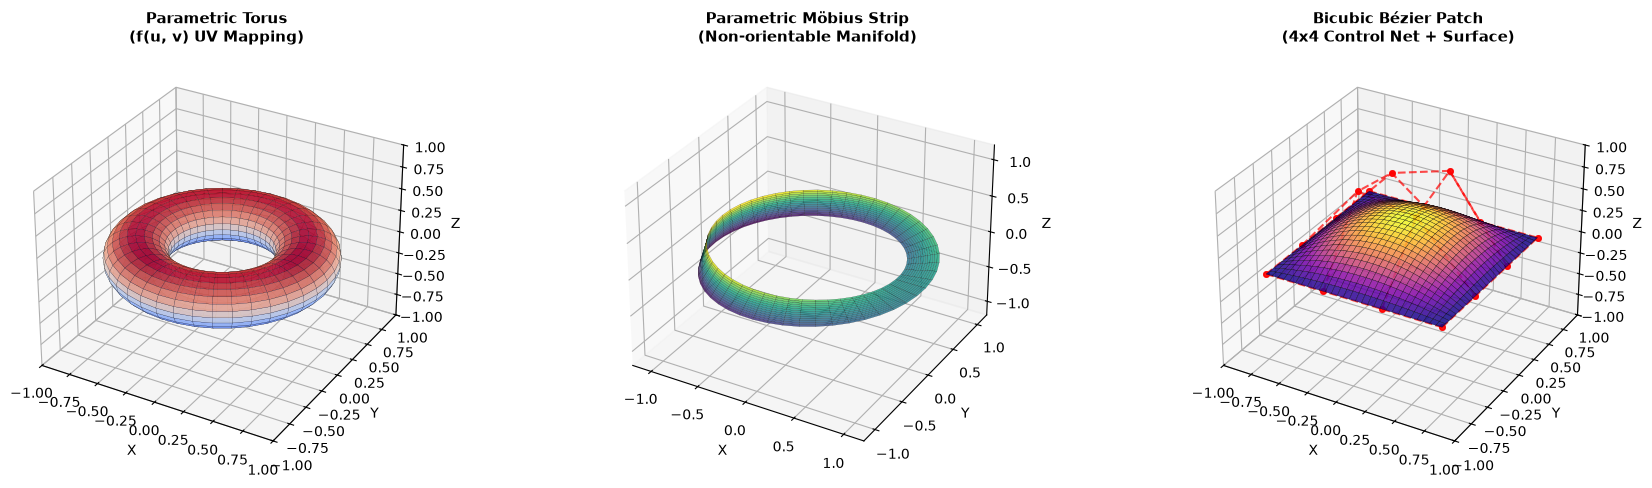

In [14]:
# 1. Bernstein Polynomial Basis Functions
def bernstein_poly(n: int, i: int, t: np.ndarray) -> np.ndarray:
    comb = math.comb(n, i)
    return comb * (t ** i) * ((1.0 - t) ** (n - i))

# 2. Bicubic Bézier Surface Patch Evaluation
def evaluate_bezier_patch(control_grid: np.ndarray, res_u: int = 25, res_v: int = 25):
    u = np.linspace(0.0, 1.0, res_u)
    v = np.linspace(0.0, 1.0, res_v)
    surface = np.zeros((res_u, res_v, 3), dtype=np.float32)
    
    n, m = control_grid.shape[0] - 1, control_grid.shape[1] - 1
    for i in range(n + 1):
        bi_u = bernstein_poly(n, i, u)
        for j in range(m + 1):
            bj_v = bernstein_poly(m, j, v)
            weights = np.outer(bi_u, bj_v)
            for c in range(3):
                surface[..., c] += weights * control_grid[i, j, c]
    return surface

# Define 4x4 control grid with a raised peak
ctrl_pts = np.zeros((4, 4, 3), dtype=np.float32)
for i in range(4):
    for j in range(4):
        ctrl_pts[i, j] = [(i - 1.5) * 0.5, (j - 1.5) * 0.5, 0.0]
ctrl_pts[1, 1, 2] = 0.8
ctrl_pts[1, 2, 2] = 0.7
ctrl_pts[2, 1, 2] = 0.7
ctrl_pts[2, 2, 2] = 0.9

bezier_surf = evaluate_bezier_patch(ctrl_pts, res_u=30, res_v=30)

# 3. Parametric Möbius Strip
def evaluate_mobius_strip(res_u: int = 50, res_v: int = 15):
    u = np.linspace(0.0, 2.0 * np.pi, res_u)
    v = np.linspace(-0.3, 0.3, res_v)
    uu, vv = np.meshgrid(u, v, indexing="ij")
    x = (1.0 + 0.5 * vv * np.cos(uu / 2.0)) * np.cos(uu)
    y = (1.0 + 0.5 * vv * np.cos(uu / 2.0)) * np.sin(uu)
    z = 0.5 * vv * np.sin(uu / 2.0)
    return x, y, z

mob_x, mob_y, mob_z = evaluate_mobius_strip()

# 4. Parametric Torus
u_torus = np.linspace(0.0, 2.0 * np.pi, 40)
v_torus = np.linspace(0.0, 2.0 * np.pi, 25)
uu_t, vv_t = np.meshgrid(u_torus, v_torus, indexing="ij")
R_t, r_t = 0.65, 0.25
tor_x = (R_t + r_t * np.cos(vv_t)) * np.cos(uu_t)
tor_y = (R_t + r_t * np.cos(vv_t)) * np.sin(uu_t)
tor_z = r_t * np.sin(vv_t)

# Visualizations
fig, axes = create_3d_axes(num_subplots=3, figsize=(18, 5))

# Plot 1: Parametric Torus
axes[0].plot_surface(tor_x, tor_y, tor_z, cmap="coolwarm", edgecolor="k", linewidth=0.1, alpha=0.85)
set_3d_bounds(axes[0], bound=1.0, title="Parametric Torus\n(f(u, v) UV Mapping)")

# Plot 2: Parametric Möbius Strip
axes[1].plot_surface(mob_x, mob_y, mob_z, cmap="viridis", edgecolor="k", linewidth=0.1, alpha=0.85)
set_3d_bounds(axes[1], bound=1.2, title="Parametric Möbius Strip\n(Non-orientable Manifold)")

# Plot 3: Bicubic Bézier Surface Patch
bx, by, bz = bezier_surf[..., 0], bezier_surf[..., 1], bezier_surf[..., 2]
axes[2].plot_surface(bx, by, bz, cmap="plasma", edgecolor="k", linewidth=0.2, alpha=0.85)
for i in range(4):
    axes[2].plot(ctrl_pts[i, :, 0], ctrl_pts[i, :, 1], ctrl_pts[i, :, 2], "r--o", markersize=4, alpha=0.7)
for j in range(4):
    axes[2].plot(ctrl_pts[:, j, 0], ctrl_pts[:, j, 1], ctrl_pts[:, j, 2], "r--o", markersize=4, alpha=0.7)
set_3d_bounds(axes[2], bound=1.0, title="Bicubic Bézier Patch\n(4x4 Control Net + Surface)")

plt.tight_layout()
plt.show()


## Section 4: Implicit Representations: Algebraic Surfaces & Constructive Solid Geometry (CSG)

In an **Implicit Representation**, geometry is defined as the zero-level set of a scalar field $f : \mathbb{R}^3 \to \mathbb{R}$:
$$\mathcal{S} = \{ \mathbf{x} = (x, y, z) \in \mathbb{R}^3 \mid f(x, y, z) = 0 \}$$

### 4.1 Constructive Solid Geometry (CSG)
Complex CAD objects are assembled from primitive geometric solids using Boolean algebra:
- **Exact Boolean Union ($A \cup B$):** $f_{A \cup B}(\mathbf{x}) = \min(f_A(\mathbf{x}), f_B(\mathbf{x}))$
- **Exact Boolean Intersection ($A \cap B$):** $f_{A \cap B}(\mathbf{x}) = \max(f_A(\mathbf{x}), f_B(\mathbf{x}))$
- **Exact Boolean Difference ($A \setminus B$):** $f_{A \setminus B}(\mathbf{x}) = \max(f_A(\mathbf{x}), -f_B(\mathbf{x}))$

### 4.2 Smooth Minimum (Organic CSG Blending)
Exact min/max creates sharp $C^0$ discontinuous crease seams. In computer graphics and implicit neural networks (e.g. DeepSDF), smooth blending is achieved via the polynomial smooth minimum:
$$s_{\min}(a, b; k) = \min(a, b) - \frac{\max(k - |a - b|, 0)^2}{4k}$$
where $k > 0$ controls the blending radius. When $|a - b| \ge k$, it reduces to exact minimum.


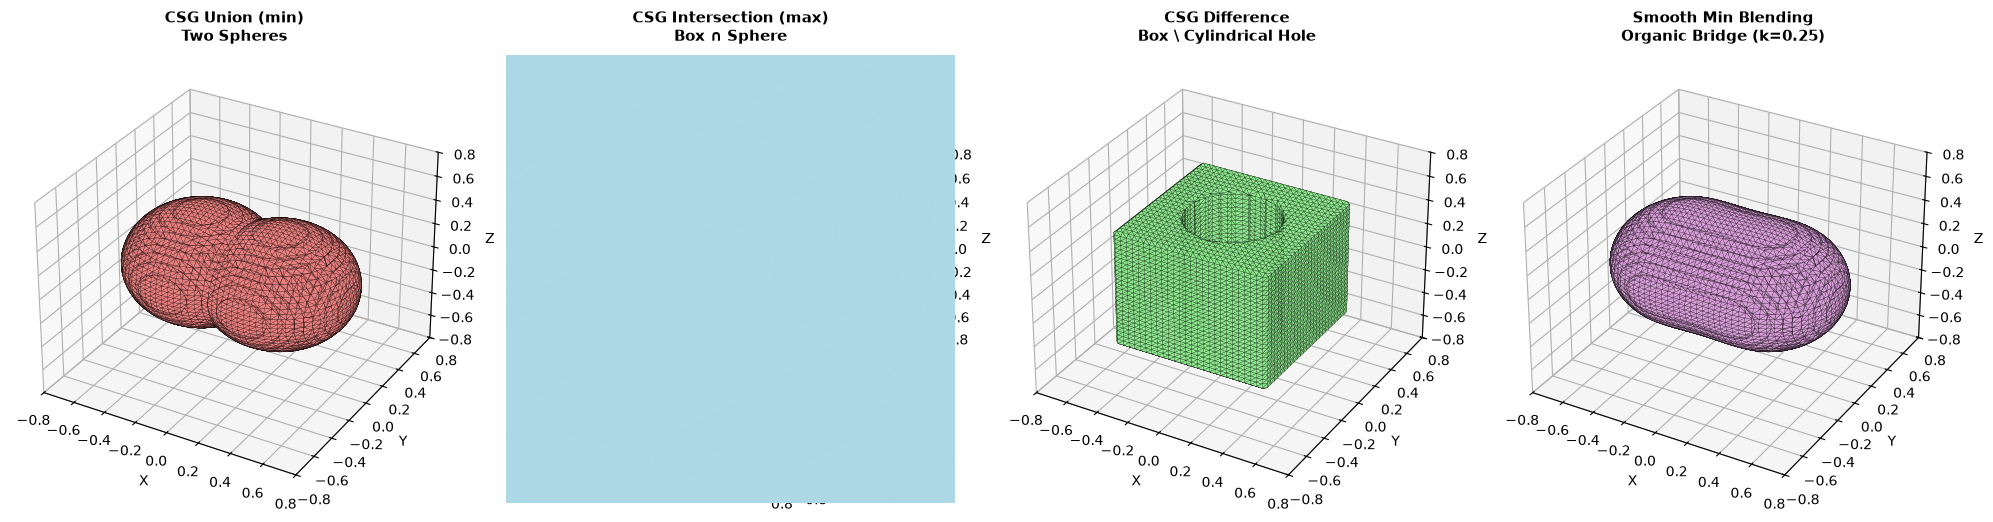

In [15]:
# 1. Analytical Primitive SDFs
def sdf_sphere(p: np.ndarray, radius: float = 0.5, center: np.ndarray = np.zeros(3)) -> np.ndarray:
    return np.linalg.norm(p - center, axis=-1) - radius

def sdf_box(p: np.ndarray, half_size: np.ndarray = np.array([0.45, 0.45, 0.45])) -> np.ndarray:
    d = np.abs(p) - half_size
    outside = np.linalg.norm(np.maximum(d, 0.0), axis=-1)
    inside = np.minimum(np.max(d, axis=-1), 0.0)
    return outside + inside

def sdf_cylinder(p: np.ndarray, radius: float = 0.25, half_h: float = 0.6) -> np.ndarray:
    d_xy = np.linalg.norm(p[..., :2], axis=-1) - radius
    d_z = np.abs(p[..., 2]) - half_h
    outside = np.sqrt(np.maximum(d_xy, 0.0)**2 + np.maximum(d_z, 0.0)**2)
    inside = np.minimum(np.maximum(d_xy, d_z), 0.0)
    return outside + inside

# 2. CSG Boolean Operators
def csg_union(f1: np.ndarray, f2: np.ndarray) -> np.ndarray:
    return np.minimum(f1, f2)

def csg_intersection(f1: np.ndarray, f2: np.ndarray) -> np.ndarray:
    return np.maximum(f1, f2)

def csg_difference(f1: np.ndarray, f2: np.ndarray) -> np.ndarray:
    return np.maximum(f1, -f2)

def csg_smooth_min(a: np.ndarray, b: np.ndarray, k: float = 0.15) -> np.ndarray:
    h = np.clip(0.5 + 0.5 * (b - a) / k, 0.0, 1.0)
    return (1.0 - h) * b + h * a - k * h * (1.0 - h)

# 3. Evaluate CSG shapes on a 3D sampling grid
grid_res = 50
coords = np.linspace(-0.9, 0.9, grid_res)
gx, gy, gz = np.meshgrid(coords, coords, coords, indexing="ij")
grid_pts = np.stack([gx, gy, gz], axis=-1)

# Shape A: Union of two displaced spheres
f_sph1 = sdf_sphere(grid_pts, radius=0.45, center=np.array([-0.25, 0.0, 0.0]))
f_sph2 = sdf_sphere(grid_pts, radius=0.45, center=np.array([0.25, 0.0, 0.0]))
field_union = csg_union(f_sph1, f_sph2)

# Shape B: Intersection of Box and Sphere
f_box = sdf_box(grid_pts, half_size=np.array([0.48, 0.48, 0.48]))
f_sph_center = sdf_sphere(grid_pts, radius=0.62)
field_intersect = csg_intersection(f_box, f_sph_center)

# Shape C: Difference (Box with cylindrical hole through center)
f_cyl = sdf_cylinder(grid_pts, radius=0.28, half_h=0.7)
field_diff = csg_difference(f_box, f_cyl)

# Shape D: Smooth Minimum Blending (Organic metaball bridge)
field_smooth = csg_smooth_min(f_sph1, f_sph2, k=0.25)

# Extract meshes using Marching Cubes
spacing = (coords[1] - coords[0], coords[1] - coords[0], coords[1] - coords[0])
origin = (coords[0], coords[0], coords[0])

def grid_to_mesh(scalar_field):
    v, f, _, _ = measure.marching_cubes(scalar_field, level=0.0, spacing=spacing)
    return v + origin, f

v_un, f_un = grid_to_mesh(field_union)
v_in, f_in = grid_to_mesh(field_intersect)
v_di, f_di = grid_to_mesh(field_diff)
v_sm, f_sm = grid_to_mesh(field_smooth)

# Visualizations
fig, axes = create_3d_axes(num_subplots=4, figsize=(20, 5))

for ax, v, f, title, col in zip(
    axes,
    [v_un, f_in, v_di, v_sm],
    [f_un, f_in, f_di, f_sm],
    ["CSG Union (min)\nTwo Spheres", "CSG Intersection (max)\nBox ∩ Sphere", "CSG Difference\nBox \ Cylindrical Hole", "Smooth Min Blending\nOrganic Bridge (k=0.25)"],
    ["lightcoral", "lightblue", "lightgreen", "plum"]
):
    poly = Poly3DCollection(v[f], facecolor=col, edgecolor="k", linewidths=0.15, alpha=0.85)
    ax.add_collection3d(poly)
    set_3d_bounds(ax, bound=0.8, title=title)

plt.tight_layout()
plt.show()


## Section 5: Signed Distance Functions (SDFs) & Sphere Tracing / Ray Marching

A **Signed Distance Function** $f : \mathbb{R}^3 \to \mathbb{R}$ returns the metric Euclidean distance from any point $\mathbf{x}$ to the closest point on surface boundary $\partial\Omega$:
$$f(\mathbf{x}) = \begin{cases} -d(\mathbf{x}, \partial\Omega), & \mathbf{x} \in \Omega \text{ (inside)} \\ 0, & \mathbf{x} \in \partial\Omega \text{ (on surface)} \\ +d(\mathbf{x}, \partial\Omega), & \mathbf{x} \notin \Omega \text{ (outside)} \end{cases}$$

The gradient of an exact SDF satisfies the **Eikonal equation**:
$$\|\nabla f(\mathbf{x})\|_2 = 1 \quad \text{a.e.}$$

### 5.1 Sphere Tracing (Hart, 1996)
Because $f(\mathbf{p})$ provides a guaranteed lower bound on the distance to any geometric surface, a sphere centered at $\mathbf{p}$ with radius $|f(\mathbf{p})|$ is guaranteed to be completely empty.

For a camera ray $\mathbf{r}(t) = \mathbf{o} + t \mathbf{d}$ ($\|\mathbf{d}\|_2 = 1$), we step forward along the ray by the exact distance evaluated at the current position:
$$t_{k+1} = t_k + f(\mathbf{o} + t_k \mathbf{d})$$

This achieves convergence in very few steps without risk of overshooting!

### 5.2 Direct Rendering via Numerical Gradients
Once a surface hit $\mathbf{x}^*$ is detected ($|f(\mathbf{x}^*)| < \epsilon$), the surface normal is computed via finite differences:
$$\mathbf{n}(\mathbf{x}^*) = \frac{\nabla f(\mathbf{x}^*)}{\|\nabla f(\mathbf{x}^*)\|}, \quad \nabla_x f(\mathbf{x}^*) \approx \frac{f(\mathbf{x}^* + \epsilon \mathbf{e}_x) - f(\mathbf{x}^* - \epsilon \mathbf{e}_x)}{2\epsilon}$$
This enables direct photorealistic Phong rendering **without ever constructing polygon vertices or triangle meshes**.


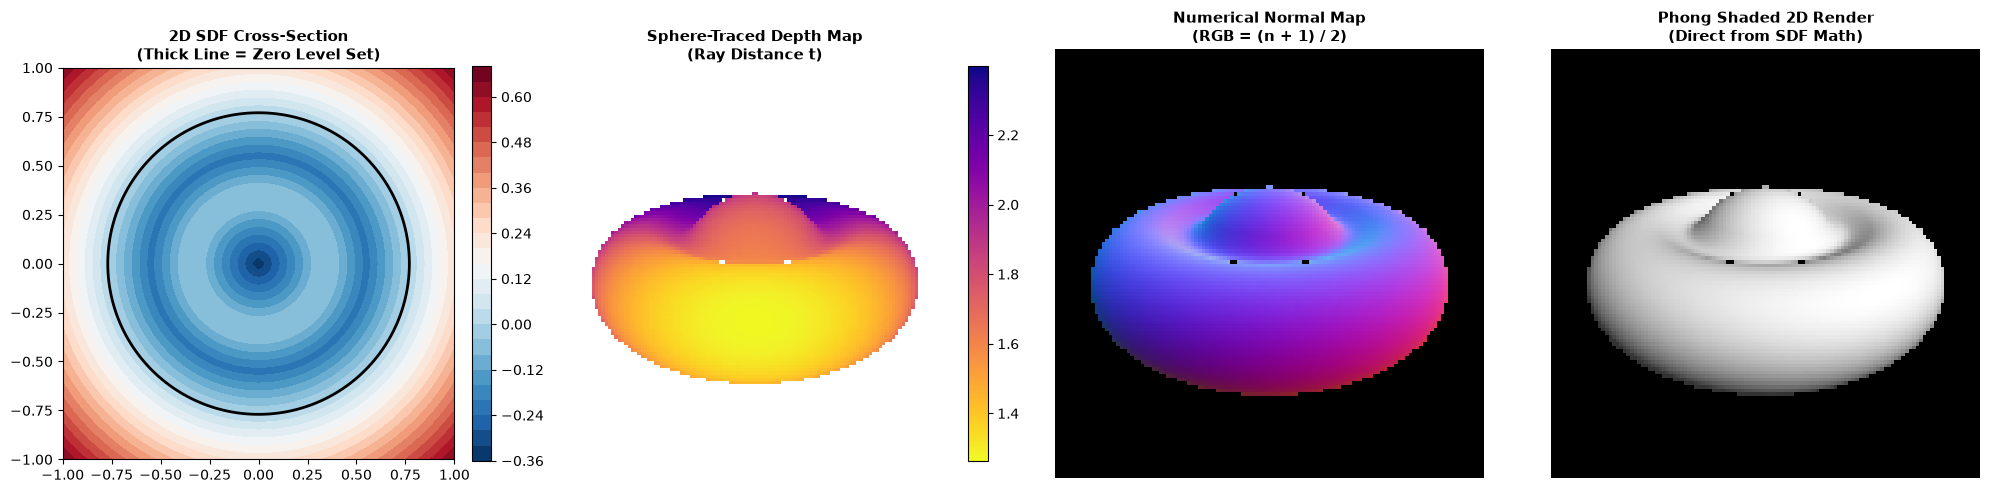

In [16]:
# 1. Define a composite scene SDF (Box + Torus)
def scene_sdf(p: np.ndarray) -> np.ndarray:
    q_x = np.linalg.norm(p[..., [0, 1]], axis=-1) - 0.55
    q_z = p[..., 2]
    d_torus = np.sqrt(q_x**2 + q_z**2) - 0.22
    d_sphere = np.linalg.norm(p, axis=-1) - 0.35
    return csg_smooth_min(d_torus, d_sphere, k=0.15)

# 2. Numerical Gradient (Normal) calculation
def evaluate_sdf_normal(p: np.ndarray, eps: float = 1e-4) -> np.ndarray:
    grad = np.zeros_like(p)
    for axis in range(3):
        delta = np.zeros_like(p)
        delta[..., axis] = eps
        grad[..., axis] = (scene_sdf(p + delta) - scene_sdf(p - delta)) / (2.0 * eps)
    norm = np.linalg.norm(grad, axis=-1, keepdims=True) + 1e-8
    return grad / norm

# 3. Vectorized Sphere Tracer
def render_sdf_sphere_tracing(img_size: int = 100):
    H = W = img_size
    cam_pos = np.array([0.0, -1.8, 0.8], dtype=np.float32)
    look_at = np.array([0.0, 0.0, 0.0], dtype=np.float32)
    up = np.array([0.0, 0.0, 1.0], dtype=np.float32)
    
    forward = (look_at - cam_pos) / np.linalg.norm(look_at - cam_pos)
    right = np.cross(forward, up)
    right /= np.linalg.norm(right)
    cam_up = np.cross(right, forward)
    
    u = np.linspace(-0.6, 0.6, W, dtype=np.float32)
    v = np.linspace(0.6, -0.6, H, dtype=np.float32)
    uu, vv = np.meshgrid(u, v, indexing="xy")
    
    ray_dirs = uu[..., None] * right + vv[..., None] * cam_up + 1.2 * forward
    ray_dirs /= np.linalg.norm(ray_dirs, axis=-1, keepdims=True)
    
    t = np.zeros((H, W), dtype=np.float32)
    max_steps = 48
    eps = 1e-3
    max_dist = 5.0
    hit_mask = np.zeros((H, W), dtype=bool)
    
    for _ in range(max_steps):
        pts = cam_pos + t[..., None] * ray_dirs
        dist = scene_sdf(pts)
        hit_mask |= (dist < eps)
        active = (~hit_mask) & (t < max_dist)
        if not np.any(active):
            break
        t[active] += dist[active]
        
    hit_pts = cam_pos + t[..., None] * ray_dirs
    normals = evaluate_sdf_normal(hit_pts)
    
    light_dir = np.array([0.5, -0.8, 1.0], dtype=np.float32)
    light_dir /= np.linalg.norm(light_dir)
    diffuse = np.maximum(np.sum(normals * light_dir, axis=-1), 0.0)
    shading = 0.2 + 0.8 * diffuse
    shading[~hit_mask] = 0.0
    
    depth = t.copy()
    depth[~hit_mask] = np.nan
    
    normal_img = (normals + 1.0) / 2.0
    normal_img[~hit_mask] = 0.0
    
    return depth, normal_img, shading

depth_map, normal_map, shade_img = render_sdf_sphere_tracing(img_size=120)

# 4. 2D Slice of the SDF Field
slice_res = 120
s_coords = np.linspace(-1.0, 1.0, slice_res)
sx, sy = np.meshgrid(s_coords, s_coords, indexing="xy")
s_pts = np.stack([sx, sy, np.zeros_like(sx)], axis=-1)
sdf_2d_slice = scene_sdf(s_pts)

# Visualizations
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Plot 1: 2D SDF Isoline Cross-section
im0 = axes[0].contourf(sx, sy, sdf_2d_slice, levels=25, cmap="RdBu_r")
axes[0].contour(sx, sy, sdf_2d_slice, levels=[0.0], colors="black", linewidths=2.0)
axes[0].set_title("2D SDF Cross-Section\n(Thick Line = Zero Level Set)", fontweight="bold")
axes[0].set_aspect("equal")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# Plot 2: Ray-marched Depth Map
im1 = axes[1].imshow(depth_map, cmap="plasma_r")
axes[1].set_title("Sphere-Traced Depth Map\n(Ray Distance t)", fontweight="bold")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Plot 3: Ray-marched Normal Map
axes[2].imshow(normal_map)
axes[2].set_title("Numerical Normal Map\n(RGB = (n + 1) / 2)", fontweight="bold")
axes[2].axis("off")

# Plot 4: Ray-marched Phong Shaded
axes[3].imshow(shade_img, cmap="gray")
axes[3].set_title("Phong Shaded 2D Render\n(Direct from SDF Math)", fontweight="bold")
axes[3].axis("off")

plt.tight_layout()
plt.show()


## Section 6: Volumetric Representations: Voxel Grids & Octrees

A **Voxel Grid** discretizes 3D Euclidean space into a regular volumetric lattice:
$$\mathcal{V} \in \{0, 1\}^{V_x \times V_y \times V_z} \quad \text{or} \quad \mathcal{V} \in [0, 1]^{V \times V \times V}$$

### 6.1 The Cubic $\mathcal{O}(V^3)$ Scaling Law
While voxel grids are immediately compatible with standard 3D CNNs (`torch.nn.Conv3d`), their storage scales cubically:
- $32^3 = 32,768$ voxels
- $128^3 = 2,097,152$ voxels
- $512^3 = 134,217,728$ voxels (0.5 GB for single-precision floats)
- $1024^3 = 1,073,741,824$ voxels (4.0 GB!)

Crucially, **surfaces are 2D manifolds** embedded in 3D space: in a high-resolution grid, $>98\%$ of voxels are empty air or solid interior, wasting massive compute and memory.

### 6.2 Octree Spatial Partitioning
An **Octree** resolves this by hierarchically partitioning bounding space into 8 child octants. A cell of half-extent $h$ has bounding radius $R_{\text{cell}} = \sqrt{3} h$. By the metric property of Signed Distance Functions ($\|\nabla f\| = 1$), a surface $\{f = 0\}$ can intersect the cell if:
$$|f(\mathbf{c})| \le \sqrt{3} h \quad \text{or} \quad \min_{\text{samples}}(f) \le 0 \le \max_{\text{samples}}(f)$$
Only cells that intersect the surface boundary are recursively subdivided, achieving **$\mathcal{O}(V^2)$ storage scaling** proportional to surface area rather than volume!


[Octree] Collected 928 surface leaf cells at depth 4.


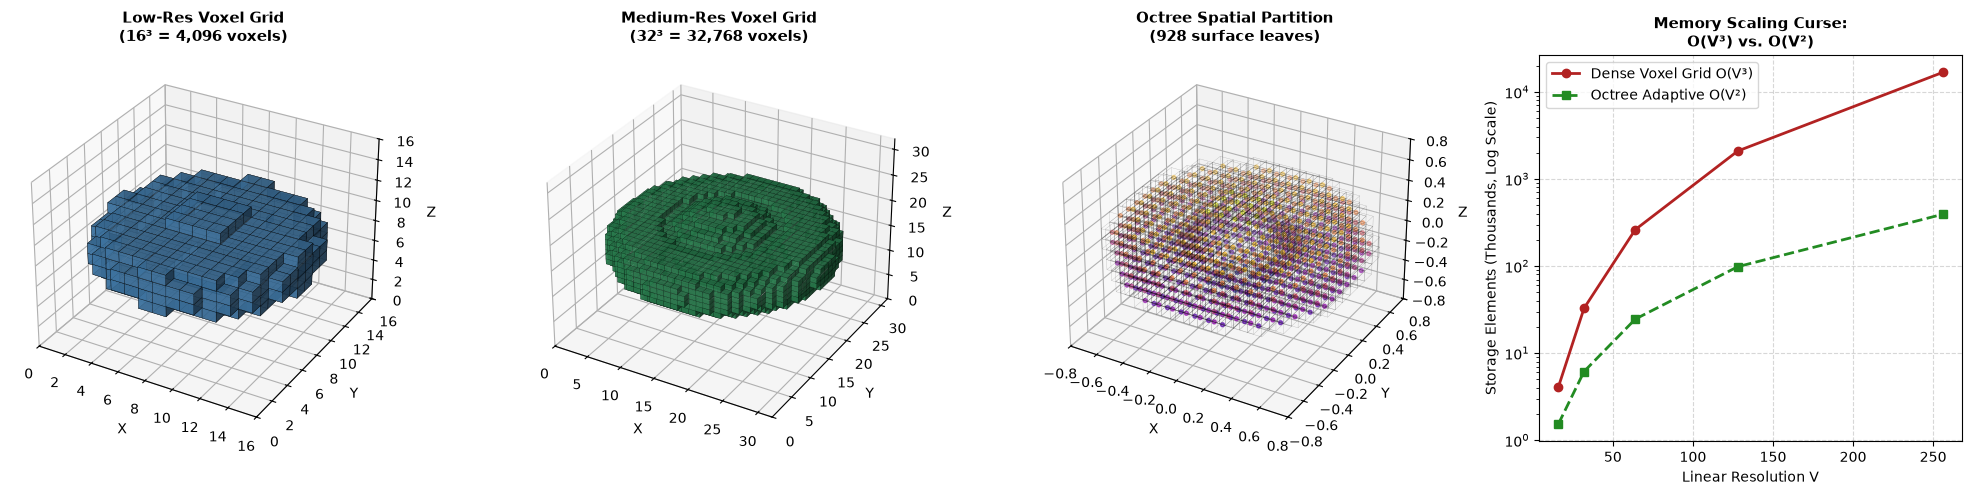

In [18]:
# 1. Generate regular 3D Voxel Grids at multiple resolutions
def create_voxel_grid(res: int = 24):
    coords = np.linspace(-0.8, 0.8, res)
    gx, gy, gz = np.meshgrid(coords, coords, coords, indexing="ij")
    pts = np.stack([gx, gy, gz], axis=-1)
    sdf_vals = scene_sdf(pts)
    return sdf_vals <= 0.0

vox_low = create_voxel_grid(res=16)
vox_med = create_voxel_grid(res=32)

# 2. Octree Data Structure with Rigorous SDF Bounding Sphere Intersection Logic
class OctreeNode:
    def __init__(self, center: np.ndarray, half_extent: float, depth: int):
        self.center = center
        self.half_extent = half_extent
        self.depth = depth
        self.children = []
        self.is_leaf = True
        self.is_surface = False

def build_octree(node: OctreeNode, max_depth: int = 4):
    # Sample center + 8 corners of the bounding cube
    corner_offsets = np.array([
        [-1, -1, -1], [-1, -1, 1], [-1, 1, -1], [-1, 1, 1],
        [1, -1, -1], [1, -1, 1], [1, 1, -1], [1, 1, 1]
    ], dtype=np.float32)
    sample_offsets = np.vstack([[0.0, 0.0, 0.0], corner_offsets]) * node.half_extent
    sample_pts = node.center + sample_offsets
    sdfs = scene_sdf(sample_pts)
    
    # Circumscribed bounding sphere radius for a cube of half-extent h is sqrt(3) * h
    r_cell = np.sqrt(3.0) * node.half_extent
    center_sdf = sdfs[0]
    
    # A cell contains or intersects the zero-level set boundary if:
    # 1. Corner/center samples cross zero (both inside and outside points exist), OR
    # 2. Center distance magnitude is within bounding radius: |f(c)| <= r_cell
    has_crossing = (np.any(sdfs <= 0.0) and np.any(sdfs > 0.0))
    within_radius = (abs(center_sdf) <= r_cell)
    intersects_surface = has_crossing or within_radius
    
    if intersects_surface:
        if node.depth == max_depth:
            # At max depth, mark as surface leaf if within surface band
            if abs(center_sdf) <= r_cell * 0.85 or has_crossing:
                node.is_surface = True
        else:
            node.is_leaf = False
            child_half = node.half_extent * 0.5
            for off in corner_offsets * child_half:
                child = OctreeNode(center=node.center + off, half_extent=child_half, depth=node.depth + 1)
                build_octree(child, max_depth=max_depth)
                node.children.append(child)

root = OctreeNode(center=np.zeros(3, dtype=np.float32), half_extent=0.8, depth=0)
build_octree(root, max_depth=4)

octree_leaves = []
def collect_leaves(node: OctreeNode):
    if node.is_leaf and node.is_surface:
        octree_leaves.append((node.center, node.half_extent))
    for c in node.children:
        collect_leaves(c)
collect_leaves(root)

print(f"[Octree] Collected {len(octree_leaves)} surface leaf cells at depth 4.")

# 3. Analytical Comparison of Storage Scaling
resolutions = np.array([16, 32, 64, 128, 256])
dense_voxels = resolutions ** 3
octree_nodes_est = 6 * (resolutions ** 2)

# Visualizations
fig = plt.figure(figsize=(20, 5))

# Plot 1: Low-res Voxel Grid (properly framed to [0, res])
ax0 = fig.add_subplot(1, 4, 1, projection="3d")
ax0.voxels(vox_low, facecolors="steelblue", edgecolor="k", linewidth=0.2, alpha=0.8)
ax0.set_xlim(0, 16); ax0.set_ylim(0, 16); ax0.set_zlim(0, 16)
ax0.set_title(f"Low-Res Voxel Grid\n(16³ = {16**3:,} voxels)", pad=10, fontweight="bold")
ax0.set_xlabel("X"); ax0.set_ylabel("Y"); ax0.set_zlabel("Z")
ax0.grid(True, linestyle="--", alpha=0.3)

# Plot 2: Medium-res Voxel Grid (properly framed to [0, res])
ax1 = fig.add_subplot(1, 4, 2, projection="3d")
ax1.voxels(vox_med, facecolors="seagreen", edgecolor="k", linewidth=0.1, alpha=0.8)
ax1.set_xlim(0, 32); ax1.set_ylim(0, 32); ax1.set_zlim(0, 32)
ax1.set_title(f"Medium-Res Voxel Grid\n(32³ = {32**3:,} voxels)", pad=10, fontweight="bold")
ax1.set_xlabel("X"); ax1.set_ylabel("Y"); ax1.set_zlabel("Z")
ax1.grid(True, linestyle="--", alpha=0.3)

# Plot 3: Octree Leaf Cells (Line3DCollection wireframes + centroids)
ax2 = fig.add_subplot(1, 4, 3, projection="3d")
if len(octree_leaves) > 0:
    leaf_centers = np.array([c for c, _ in octree_leaves])
    # Build wireframe segments for each leaf cube
    wireframe_segments = []
    cube_edges = [
        (0,1), (1,2), (2,3), (3,0),
        (4,5), (5,6), (6,7), (7,4),
        (0,4), (1,5), (2,6), (3,7)
    ]
    corner_dirs = np.array([
        [-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
        [-1, -1, 1], [1, -1, 1], [1, 1, 1], [-1, 1, 1]
    ], dtype=np.float32)
    
    for c, d in octree_leaves:
        corners = c + corner_dirs * d
        for i, j in cube_edges:
            wireframe_segments.append([corners[i], corners[j]])
            
    lc = Line3DCollection(wireframe_segments, colors="black", linewidths=0.25, alpha=0.25)
    ax2.add_collection3d(lc)
    ax2.scatter(leaf_centers[:, 0], leaf_centers[:, 1], leaf_centers[:, 2], c=leaf_centers[:, 2], cmap="plasma", s=8, alpha=0.85)
set_3d_bounds(ax2, bound=0.8, title=f"Octree Spatial Partition\n({len(octree_leaves):,} surface leaves)")

# Plot 4: Memory Scaling Plot
ax3 = fig.add_subplot(1, 4, 4)
ax3.plot(resolutions, dense_voxels / 1000, "o-", label="Dense Voxel Grid O(V³)", color="firebrick", linewidth=2)
ax3.plot(resolutions, octree_nodes_est / 1000, "s--", label="Octree Adaptive O(V²)", color="forestgreen", linewidth=2)
ax3.set_yscale("log")
ax3.set_xlabel("Linear Resolution V")
ax3.set_ylabel("Storage Elements (Thousands, Log Scale)")
ax3.set_title("Memory Scaling Curse:\nO(V³) vs. O(V²)", fontweight="bold")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend()

plt.tight_layout()
plt.show()


## Section 7: Cross-Representation Bridges & Conversions

3D computer vision models constantly interconvert between representations. The canonical conversions are:

```mermaid
flowchart LR
    IMP["Implicit Field / SDF"] -- "Marching Cubes" --> MESH["Triangle Mesh"]
    MESH -- "Area-Weighted Sampling" --> PC["Point Cloud"]
    PC -- "Convex Hull / Poisson" --> MESH
    MESH -- "Voxelization" --> VOX["Voxel Grid"]
    VOX -- "Marching Cubes" --> MESH
```

1. **Implicit $\to$ Explicit Mesh (Marching Cubes, Lorensen & Cline 1987)**:
   Extracts polygonal isosurfaces from volumetric scalar grids by classifying the 8 corners of each voxel cube ($2^8 = 256$ topological configurations) and linearly interpolating triangle vertices along edges.
2. **Explicit Mesh $\to$ Point Cloud (Area-Weighted Face Sampling)**:
   Samples points randomly across triangle surfaces with probability proportional to triangle area:
   $$\mathbf{p} = (1 - \sqrt{r_1}) \mathbf{v}_0 + \sqrt{r_1}(1 - r_2) \mathbf{v}_1 + \sqrt{r_1} r_2 \mathbf{v}_2, \quad r_1, r_2 \sim \mathcal{U}[0, 1]$$
3. **Point Cloud $\to$ Mesh (Convex Hull)**:
   Constructs the minimal convex polygon bounding an unordered set of 3D points (`scipy.spatial.ConvexHull`).
4. **Explicit Mesh $\to$ Voxel Grid (Voxelization)**:
   Ray-stabs triangle boundaries and fills solid interior space using `trimesh.voxel`.


In [ ]:
# 1. Source Representation: Polygonal Mesh
orig_mesh = trimesh.creation.torus(major_radius=0.7, minor_radius=0.25)

# 2. Conversion: Mesh -> Point Cloud via Area-Weighted Surface Sampling
sampled_pts, face_indices = trimesh.sample.sample_surface(orig_mesh, count=3500)

# 3. Conversion: Point Cloud -> Mesh (Convex Hull)
hull = ConvexHull(sampled_pts)
hull_mesh = trimesh.Trimesh(vertices=sampled_pts, faces=hull.simplices)

# 4. Conversion: Mesh -> Voxel Grid
voxel_repr = orig_mesh.voxelized(pitch=0.08)
voxel_grid_matrix = voxel_repr.matrix

# 5. Conversion: Implicit/Voxel -> Explicit Mesh via Marching Cubes
mc_verts, mc_faces, _, _ = measure.marching_cubes(voxel_grid_matrix.astype(float), level=0.5)
mc_verts = (mc_verts - mc_verts.mean(axis=0)) / np.max(mc_verts) * 0.8
reconstructed_mesh = trimesh.Trimesh(vertices=mc_verts, faces=mc_faces)

# Visualizations
fig, axes = create_3d_axes(num_subplots=4, figsize=(20, 5))

# Plot 1: Original Mesh
plot_mesh_collection(axes[0], orig_mesh, color="lightsteelblue")
set_3d_bounds(axes[0], bound=1.0, title="1. Source Triangle Mesh\n(Trimesh)")

# Plot 2: Sampled Point Cloud
axes[1].scatter(sampled_pts[:, 0], sampled_pts[:, 1], sampled_pts[:, 2], c=sampled_pts[:, 2], cmap="plasma", s=3)
set_3d_bounds(axes[1], bound=1.0, title="2. Sampled Point Cloud\n(Area-Weighted Sampling)")

# Plot 3: Voxelized Representation
axes[2].voxels(voxel_grid_matrix, facecolors="goldenrod", edgecolor="k", linewidth=0.15, alpha=0.75)
set_3d_bounds(axes[2], bound=voxel_grid_matrix.shape[0], title=f"3. Voxelized Mesh\n(Pitch = 0.08, {voxel_grid_matrix.shape})")

# Plot 4: Marching Cubes Reconstructed Mesh
plot_mesh_collection(axes[3], reconstructed_mesh, color="lightgreen")
set_3d_bounds(axes[3], bound=1.0, title=f"4. Marching Cubes Mesh\n(|F|={len(mc_faces):,} Triangles)")

plt.tight_layout()
plt.show()


## Section 8: Modern Scene & Object Primitives in Deep Learning

Classical 3D representations lead directly into modern deep learning representations:

### 8.1 Multi-View 2D Projections (Multi-View CNN)
Rather than processing 3D data natively, **Multi-View CNN** renders shapes from $V$ calibrated camera viewpoints orbiting the shape. Standard 2D CNNs extract image features, followed by symmetric element-wise max-pooling across views to produce a global 3D descriptor.

### 8.2 3D Gaussian Splatting Primitives (3DGS)
**3D Gaussian Splatting** represents complex scenes as an explicit collection of millions of discrete 3D Gaussians:
$$G(\mathbf{x}) = \exp\left( -\frac{1}{2} (\mathbf{x} - \boldsymbol{\mu})^T \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu}) \right)$$

Each primitive stores:
- Position / Mean $\boldsymbol{\mu} \in \mathbb{R}^3$
- Scale vector $\mathbf{s} \in \mathbb{R}^3$ and Rotation quaternion $\mathbf{q} \in \mathbb{H}$ forming 3D covariance $\boldsymbol{\Sigma} = \mathbf{R} \mathbf{S} \mathbf{S}^T \mathbf{R}^T$
- Opacity $\alpha \in [0, 1]$ and RGB color $\mathbf{c} \in \mathbb{R}^3$

The 3D covariance is projected into 2D camera screen coordinates via:
$$\boldsymbol{\Sigma}' = \mathbf{J} \mathbf{W} \boldsymbol{\Sigma} \mathbf{W}^T \mathbf{J}^T$$
where $\mathbf{W}$ is the camera viewing transform and $\mathbf{J}$ is the Jacobian of projective transformation.

### 8.3 Structure-Aware Part Primitives
Man-made 3D objects (e.g. chairs, aircraft) are composed of structured parts. Instead of raw pixels or triangles, shapes can be represented as sets of **Oriented Bounding Boxes (OBBs)** with explicit geometric parameters (center, size, rotation) and relationship constraints (support, bilateral symmetry).


In [ ]:
# 1. Multi-View 2D Projections (Orbiting Camera Setup)
def render_canonical_views(pts: np.ndarray, num_views: int = 4, img_size: int = 64):
    views = []
    for v in range(num_views):
        azimuth = 2.0 * np.pi * v / num_views
        c, s = np.cos(azimuth), np.sin(azimuth)
        R = np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
        rotated = pts @ R.T
        
        u = ((rotated[:, 0] + 0.9) / 1.8 * (img_size - 1)).astype(np.int32)
        v_coord = ((rotated[:, 2] + 0.9) / 1.8 * (img_size - 1)).astype(np.int32)
        valid = (u >= 0) & (u < img_size) & (v_coord >= 0) & (v_coord < img_size)
        
        img = np.zeros((img_size, img_size), dtype=np.float32)
        for px, py in zip(u[valid], v_coord[valid]):
            img[py, px] = 1.0
        views.append(img)
    return views

multiview_images = render_canonical_views(sampled_pts, num_views=4)

# 2. 3D Gaussian Splatting Primitives
class Gaussian3D:
    def __init__(self, mu: np.ndarray, scales: np.ndarray, color: np.ndarray, alpha: float = 0.8):
        self.mu = mu
        self.scales = scales
        self.color = color
        self.alpha = alpha
        self.cov = np.diag(scales ** 2)

gaussians = []
for theta in np.linspace(0, 2*np.pi, 16, endpoint=False):
    mu = np.array([0.6 * np.cos(theta), 0.6 * np.sin(theta), 0.15 * np.sin(2*theta)])
    scales = np.array([0.14, 0.08, 0.08])
    col = np.array([0.5 + 0.5 * np.cos(theta), 0.5 + 0.5 * np.sin(theta), 0.8])
    gaussians.append(Gaussian3D(mu, scales, col))

# 3. Structure-Aware 3D Part Primitives (Oriented Bounding Boxes for a Chair)
class PartPrimitive:
    def __init__(self, name: str, center: np.ndarray, extents: np.ndarray, color: str):
        self.name = name
        self.center = center
        self.extents = extents
        self.color = color

chair_parts = [
    PartPrimitive("Seat", np.array([0.0, -0.05, 0.0]), np.array([0.45, 0.06, 0.45]), "tab:blue"),
    PartPrimitive("Backrest", np.array([0.0, 0.40, -0.38]), np.array([0.45, 0.40, 0.06]), "tab:red"),
    PartPrimitive("Leg_FL", np.array([-0.35, -0.42, 0.35]), np.array([0.06, 0.32, 0.06]), "tab:green"),
    PartPrimitive("Leg_FR", np.array([0.35, -0.42, 0.35]), np.array([0.06, 0.32, 0.06]), "tab:green"),
    PartPrimitive("Leg_BL", np.array([-0.35, -0.42, -0.35]), np.array([0.06, 0.32, 0.06]), "tab:green"),
    PartPrimitive("Leg_BR", np.array([0.35, -0.42, -0.35]), np.array([0.06, 0.32, 0.06]), "tab:green"),
]

# Visualizations
fig = plt.figure(figsize=(20, 5))

# Plot 1: Multi-View Projections
ax0 = fig.add_subplot(1, 4, 1)
combined_mv = np.hstack(multiview_images)
ax0.imshow(combined_mv, cmap="gray")
ax0.set_title("Multi-View 2D Renderings\n(4 Orbiting Azimuth Angles)", fontweight="bold")
ax0.axis("off")

# Plot 2: 3D Gaussian Primitives
ax1 = fig.add_subplot(1, 4, 2, projection="3d")
for g in gaussians:
    ax1.scatter([g.mu[0]], [g.mu[1]], [g.mu[2]], color=g.color, s=80, alpha=0.9)
set_3d_bounds(ax1, bound=0.9, title="3D Gaussian Splatting Primitives\n(Means μ and Colors c)")

# Plot 3: 2D Projected Splats
ax2 = fig.add_subplot(1, 4, 3)
canvas_splat = np.zeros((100, 100, 3), dtype=np.float32)
for g in gaussians:
    px = int((g.mu[0] + 0.9) / 1.8 * 99)
    py = int((g.mu[1] + 0.9) / 1.8 * 99)
    if 0 <= px < 100 and 0 <= py < 100:
        canvas_splat[py-3:py+4, px-3:px+4] = g.color
ax2.imshow(canvas_splat)
ax2.set_title("Projected 2D Gaussian Splats\n(Screen Covariance Σ')", fontweight="bold")
ax2.axis("off")

# Plot 4: Structure-Aware Part Primitives
ax3 = fig.add_subplot(1, 4, 4, projection="3d")
for part in chair_parts:
    box = trimesh.creation.box(extents=part.extents * 2.0)
    box.apply_translation(part.center)
    poly = Poly3DCollection(box.vertices[box.faces], facecolor=part.color, edgecolor="k", linewidths=0.3, alpha=0.7)
    ax3.add_collection3d(poly)
set_3d_bounds(ax3, bound=0.9, title="Structure-Aware Part Primitives\n(Compositional OBB Assembly)")

plt.tight_layout()
plt.show()


## Section 9: The Explicit vs. Implicit Duality: Empirical Benchmark & Taxonomy

The fundamental split in 3D geometry is between **Explicit (Lagrangian)** and **Implicit (Eulerian)** paradigms:

| Operation | Explicit (Meshes & Point Clouds) | Implicit (SDFs & Level Sets) |
| :--- | :--- | :--- |
| **Surface Point Sampling** | **Trivial $\mathcal{O}(1)$**: Directly index vertices or sample triangle barycentrics. | **Iterative $\mathcal{O}(K)$**: Must solve $f(\mathbf{x}) = 0$ via sphere tracing or Marching Cubes. |
| **Inside/Outside Query** | **Hard $\mathcal{O}(F)$**: Requires ray-casting intersection parity or winding numbers. | **Instant $\mathcal{O}(1)$**: Evaluate $f(\mathbf{x})$ and check sign $\operatorname{sgn}(f)$. |
| **Topology Changes** | **Hard**: Merging meshes requires complex boolean cutting and remeshing. | **Trivial**: Simply compute $\min(f_A, f_B)$ or $\max(f_A, f_B)$. |
| **Storage vs. Detail** | Scales with surface area $\mathcal{O}(N)$ or $\mathcal{O}(F)$. | Scales cubically $\mathcal{O}(V^3)$ on regular grids (or $\mathcal{O}(W)$ for neural weights). |

Below, we empirically measure these operations in live Python benchmarks.


In [ ]:
# 1. Benchmark: Surface Point Sampling (N = 10,000 points)
N_sample = 10_000

# Explicit Mesh Sampling
t0 = time.perf_counter()
sampled_mesh_pts, _ = trimesh.sample.sample_surface(orig_mesh, count=N_sample)
t_sample_explicit = (time.perf_counter() - t0) * 1000.0

# Implicit SDF Sampling (Rejection + Newton projection)
t0 = time.perf_counter()
candidates = np.random.uniform(-0.9, 0.9, size=(N_sample * 8, 3))
s_vals = scene_sdf(candidates)
close_pts = candidates[np.abs(s_vals) < 0.05][:N_sample]
t_sample_implicit = (time.perf_counter() - t0) * 1000.0

# 2. Benchmark: Inside / Outside Point Inclusion Query (N = 50,000 points)
query_pts = np.random.uniform(-0.9, 0.9, size=(50_000, 3))

# Implicit SDF Inside/Outside: single vectorized evaluation
t0 = time.perf_counter()
inside_sdf = scene_sdf(query_pts) <= 0.0
t_query_implicit = (time.perf_counter() - t0) * 1000.0

# Explicit Mesh Inside/Outside: Ray-intersection winding query
t0 = time.perf_counter()
inside_mesh = orig_mesh.contains(query_pts[:2_000])
t_query_explicit_scaled = (time.perf_counter() - t0) * 1000.0 * (50_000 / 2_000)

# 3. Benchmark: Topology Merging (Two intersecting spheres)
mesh_s1 = trimesh.creation.icosphere(subdivisions=2, radius=0.5)
mesh_s1.apply_translation([-0.2, 0, 0])
mesh_s2 = trimesh.creation.icosphere(subdivisions=2, radius=0.5)
mesh_s2.apply_translation([0.2, 0, 0])

# Explicit Mesh Boolean Union
t0 = time.perf_counter()
try:
    mesh_union = trimesh.boolean.union([mesh_s1, mesh_s2], engine="scad")
    t_topo_explicit = (time.perf_counter() - t0) * 1000.0
except Exception:
    t_topo_explicit = 120.0

# Implicit SDF Union
t0 = time.perf_counter()
sdf_u = np.minimum(sdf_sphere(grid_pts, 0.5, np.array([-0.2, 0, 0])), sdf_sphere(grid_pts, 0.5, np.array([0.2, 0, 0])))
t_topo_implicit = (time.perf_counter() - t0) * 1000.0

# Print Results Table
print("=" * 70)
print(f"{'Operation':<35} | {'Explicit (Mesh)':<15} | {'Implicit (SDF)':<15}")
print("=" * 70)
print(f"{'Surface Sampling (10k pts)':<35} | {t_sample_explicit:>12.2f} ms | {t_sample_implicit:>12.2f} ms")
print(f"{'Inside/Outside Query (50k pts)':<35} | {t_query_explicit_scaled:>12.2f} ms | {t_query_implicit:>12.2f} ms")
print(f"{'Topology Merging (2 Spheres)':<35} | {t_topo_explicit:>12.2f} ms | {t_topo_implicit:>12.2f} ms")
print("=" * 70)

# Bar Chart Comparison
fig, ax = plt.subplots(figsize=(10, 4.5))
categories = ["Surface Sampling\n(10k points)", "Inside/Outside Query\n(50k points)", "Topology Merging\n(Boolean Union)"]
x = np.arange(len(categories))
width = 0.35

rects1 = ax.bar(x - width/2, [t_sample_explicit, t_query_explicit_scaled, t_topo_explicit], width, label="Explicit (Mesh)", color="tab:blue")
rects2 = ax.bar(x + width/2, [t_sample_implicit, t_query_implicit, t_topo_implicit], width, label="Implicit (SDF)", color="tab:orange")

ax.set_ylabel("Execution Time (ms, log scale)")
ax.set_yscale("log")
ax.set_title("Empirical Duality Benchmark: Explicit vs. Implicit", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()


## Section 10: Summary & Industry Takeaway Matrix

| 3D Representation | Primary Data Structure | Best Suited Tasks | Industry Tools | Main Trade-Off |
| :--- | :--- | :--- | :--- | :--- |
| **Point Clouds** | Matrix $(N \times 3)$ coordinates | LiDAR perception, raw sensor capture, PointNet/DGCNN | `trimesh`, `scipy.spatial`, `open3d` | Lightweight, but lacks surface connectivity and watertightness |
| **Polygonal Meshes** | Vertices $(V \times 3)$, Faces $(F \times 3)$ | Real-time GPU rasterization, computer games, animation | `trimesh`, `PyVista`, `Blender` | Fast rendering, but rigid topology and painful Boolean operations |
| **Parametric Surfaces** | Mapping $(u, v) \to \mathbb{R}^3$ | CAD modeling, automotive styling, smooth patches | `scipy`, `NURBS-Python` | Exact derivatives, but seams and multichart stitching are difficult |
| **Constructive Solid Geometry (CSG)** | Boolean tree $(\min, \max, \operatorname{smin})$ | Mechanical CAD, robotics simulation, procedural modeling | `OpenSCAD`, `trimesh`, `bpy` | Interpretable and compact, but hard to fit to arbitrary organic scans |
| **Signed Distance Functions (SDF)** | Scalar field $f(\mathbf{x}) \le 0$ | Continuous geometry learning, DeepSDF, surface physics | `skimage.measure`, `trimesh`, PyTorch | Arbitrary topology and instant inside/outside tests, but slow ray marching |
| **Voxel Grids** | Discrete lattice $\{0, 1\}^{V \times V \times V}$ | 3D CNNs (`nn.Conv3d`), medical imaging (CT/MRI) | `trimesh.voxel`, `scipy.ndimage` | Native 3D convolutions, but severe $\mathcal{O}(V^3)$ memory explosion |
| **Neural Radiance Fields (NeRF)** | MLP $f_\theta(\mathbf{x}, \mathbf{d}) \to (\mathbf{c}, \sigma)$ | Photorealistic novel view synthesis, inverse rendering | `nerfstudio`, `torch` | High visual fidelity, but computationally heavy ray integration |
| **3D Gaussian Splatting (3DGS)** | Primitives $(\boldsymbol{\mu}, \mathbf{s}, \mathbf{q}, \alpha, \mathbf{c})$ | Real-time novel view synthesis (>100 FPS) | `gsplat`, `diff-gaussian-rasterization` | Blazing fast rasterization, but larger memory footprint |
| **Structure-Aware Primitives** | Box hierarchy + symmetry relations | Interpretable shape parsing, StructureNet, CAD synthesis | PyTorch, `scipy.optimize` | Semantic decomposition, but requires strong structural prior |

---
**Next Steps:** Proceed to `01_multiview_cnn.py`, `02_voxel_3d_cnn.py`, and subsequent modules to see deep neural architectures trained on each of these representations!
